# The Promotion Paradox — Data Prep + Visualization Setup

This notebook intentionally contains only:

1. data loading / cleaning,
2. filtering and transformations needed for the two draft visualizations,
3. lightweight setup code for the two visualizations.

It does **not** include the later year-adjustment diagnostic, interpretation, ethical reflection, or final prose.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_PATH = "allegations_202007271729.csv"

df = pd.read_csv(DATA_PATH, low_memory=False)

print(f"Rows: {len(df):,}")
print(f"Columns: {df.shape[1]}")


Rows: 33,358
Columns: 27


## 1. Keep the variables needed for the two drafts


In [2]:
cols = [
    "unique_mos_id",
    "complaint_id",
    "year_received",
    "rank_incident",
    "board_disposition",
]

data = df[cols].copy()

data.head()


,unique_mos_id,complaint_id,year_received,rank_incident,board_disposition
0,10004,42835,2019,Police Officer,Substantiated (Command Lvl Instructions)
1,10007,24601,2011,Police Officer,Substantiated (Charges)
2,10007,24601,2011,Police Officer,Substantiated (Charges)
3,10007,26146,2012,Police Officer,Substantiated (Charges)
4,10009,40253,2018,Police Officer,Substantiated (Command Discipline A)


## 2. Clean rank and disposition fields

Each row in this dataset is an **allegation**.  
For these drafts, an allegation is coded as substantiated when `board_disposition`
starts with `"Substantiated"`.


In [3]:
data["rank_incident"] = data["rank_incident"].astype("string").str.strip()
data["board_disposition"] = data["board_disposition"].astype("string").str.strip()

data["substantiated"] = (
    data["board_disposition"]
        .str.lower()
        .str.startswith("substantiated", na=False)
)

data["substantiated"] = data["substantiated"].astype(int)

data[["rank_incident", "board_disposition", "substantiated"]].head()


,rank_incident,board_disposition,substantiated
0,Police Officer,Substantiated (Command Lvl Instructions),1
1,Police Officer,Substantiated (Charges),1
2,Police Officer,Substantiated (Charges),1
3,Police Officer,Substantiated (Charges),1
4,Police Officer,Substantiated (Command Discipline A),1


# Visualization 1 setup
## Officer-weighted substantiation rate by rank

The first draft compares **average officer-level substantiation rates** for:

- Police Officer
- Sergeant
- Lieutenant

First, calculate each officer's substantiation rate separately at each rank. Then average those officer-level rates within each rank, so **each officer receives equal weight**.


In [4]:
rank_order = ["Police Officer", "Sergeant", "Lieutenant"]

viz1_source = data[
    data["rank_incident"].isin(rank_order)
].copy()


officer_rank_rates = (
    viz1_source
    .groupby(["unique_mos_id", "rank_incident"], observed=True)
    ["substantiated"]
    .mean()
    .reset_index(name="officer_substantiation_rate")
)


viz1_data = (
    officer_rank_rates
    .groupby("rank_incident", observed=True)
    .agg(
        num_officers=("unique_mos_id", "nunique"),
        substantiation_rate=("officer_substantiation_rate", "mean"),
    )
    .reindex(rank_order)
    .reset_index()
)

viz1_data["substantiation_pct"] = 100 * viz1_data["substantiation_rate"]

viz1_data


,rank_incident,num_officers,substantiation_rate,substantiation_pct
0,Police Officer,3606,0.373332,37.333171
1,Sergeant,852,0.309019,30.901862
2,Lieutenant,213,0.237480,23.747996


### Draft Visualization 1

The bars share a common 0% baseline, and bar length represents the **average officer-level substantiation rate** at each rank.


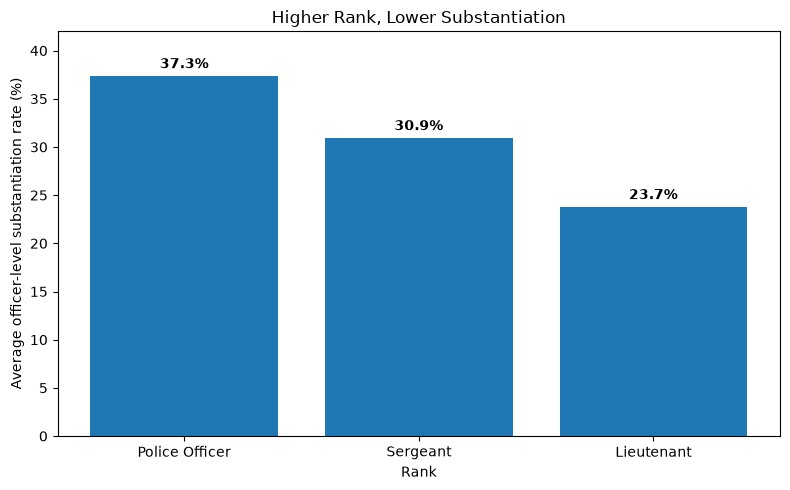

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    viz1_data["rank_incident"],
    viz1_data["substantiation_pct"]
)

for bar, rate in zip(bars, viz1_data["substantiation_pct"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{rate:.1f}%",
        ha="center",
        va="bottom",
        fontweight="bold"
    )

ax.set_xlabel("Rank")
ax.set_ylabel("Average officer-level substantiation rate (%)")
ax.set_title("Higher Rank, Lower Substantiation")

ax.set_ylim(0, 42)

plt.tight_layout()
plt.show()

# Visualization 2 setup
## Same officers observed as both Police Officer and Sergeant

The final displayed rates are **equal-weight officer-level means**: each matched
officer contributes one Police Officer rate and one Sergeant rate.


In [6]:
po_sgt = data[
    data["rank_incident"].isin(["Police Officer", "Sergeant"])
].copy()

officer_rank = (
    po_sgt
    .groupby(["unique_mos_id", "rank_incident"], observed=True)
    .agg(
        allegations=("substantiated", "size"),
        substantiated_allegations=("substantiated", "sum"),
        substantiation_rate=("substantiated", "mean"),
        first_year=("year_received", "min"),
        last_year=("year_received", "max"),
    )
    .reset_index()
)

officer_rank.head()


,unique_mos_id,rank_incident,allegations,substantiated_allegations,substantiation_rate,first_year,last_year
0,2,Sergeant,10,1,0.1,2009,2013
1,5,Police Officer,1,0,0.0,2011,2011
2,5,Sergeant,2,1,0.5,2015,2016
3,11,Police Officer,5,2,0.4,2007,2012
4,21,Police Officer,8,4,0.5,2006,2011


In [7]:
wide = officer_rank.pivot(
    index="unique_mos_id",
    columns="rank_incident",
    values=[
        "allegations",
        "substantiation_rate",
        "first_year",
        "last_year",
    ],
)

wide.head()

allegations          substantiation_rate           \
rank_incident Police Officer Sergeant      Police Officer Sergeant   
unique_mos_id                                                        
2                        NaN     10.0                 NaN      0.1   
5                        1.0      2.0            0.000000      0.5   
11                       5.0      NaN            0.400000      NaN   
21                       8.0      NaN            0.500000      NaN   
23                      14.0      NaN            0.071429      NaN   

                  first_year               last_year           
rank_incident Police Officer Sergeant Police Officer Sergeant  
unique_mos_id                                                  
2                        NaN   2009.0            NaN   2013.0  
5                     2011.0   2015.0         2011.0   2016.0  
11                    2007.0      NaN         2012.0      NaN  
21                    2006.0      NaN         2011.0      NaN  
23                    2008.0      NaN         2013.0      NaN

In [8]:
# Keep officers observed at BOTH ranks.
matched = wide.dropna(
    subset=[
        ("substantiation_rate", "Police Officer"),
        ("substantiation_rate", "Sergeant"),
    ]
).copy()


# first observed Sergeant year is not earlier than first observed Police Officer year
matched = matched[
    matched[("first_year", "Sergeant")]
    >= matched[("first_year", "Police Officer")]
].copy()

print(f"Matched officers: {len(matched):,}")
matched.head()


Matched officers: 594


allegations          substantiation_rate           \
rank_incident Police Officer Sergeant      Police Officer Sergeant   
unique_mos_id                                                        
5                        1.0      2.0            0.000000      0.5   
208                      3.0      1.0            0.666667      0.0   
216                      1.0      1.0            0.000000      0.0   
289                      1.0      1.0            0.000000      1.0   
513                      4.0      1.0            0.500000      0.0   

                  first_year               last_year           
rank_incident Police Officer Sergeant Police Officer Sergeant  
unique_mos_id                                                  
5                     2011.0   2015.0         2011.0   2016.0  
208                   2007.0   2017.0         2008.0   2017.0  
216                   2006.0   2013.0         2006.0   2013.0  
289                   2012.0   2017.0         2012.0   2017.0  
513                   2009.0   2014.0         2010.0   2014.0

In [9]:
viz2_data = pd.DataFrame({
    "rank": ["Police Officer", "Sergeant"],
    "mean_officer_substantiation_pct": [
        100 * matched[("substantiation_rate", "Police Officer")].mean(),
        100 * matched[("substantiation_rate", "Sergeant")].mean(),
    ],
})

viz2_data["difference_from_po_pp"] = (
    viz2_data["mean_officer_substantiation_pct"]
    - viz2_data.loc[
        viz2_data["rank"] == "Police Officer",
        "mean_officer_substantiation_pct"
    ].iloc[0]
)

viz2_data


,rank,mean_officer_substantiation_pct,difference_from_po_pp
0,Police Officer,16.536242,0.000000
1,Sergeant,25.236615,8.700373


### Draft Visualization 2

This prototype emphasizes that the comparison uses the **same matched officers**.


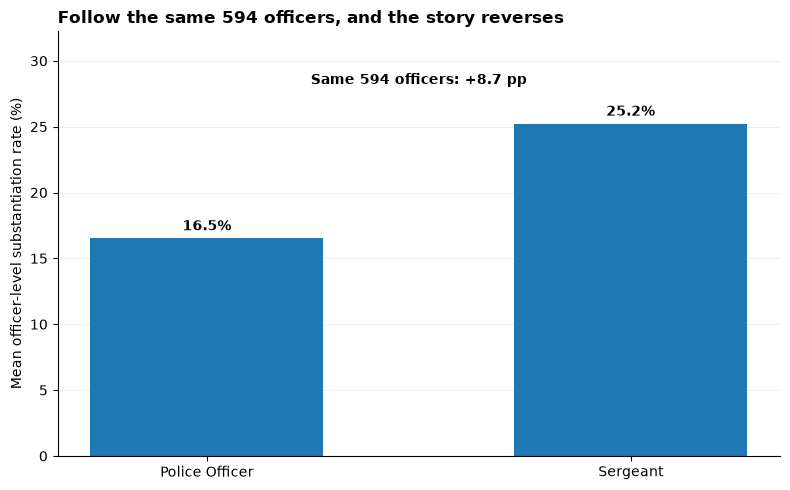

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))

x = np.arange(len(viz2_data))
rates = viz2_data["mean_officer_substantiation_pct"].to_numpy()

ax.bar(x, rates, width=0.55)

for xi, rate in zip(x, rates):
    ax.text(xi, rate + 0.6, f"{rate:.1f}%", ha="center", fontweight="bold")

difference = rates[1] - rates[0]
ax.text(
    0.5,
    max(rates) + 3.0,
    f"Same {len(matched):,} officers: +{difference:.1f} pp",
    ha="center",
    fontweight="bold",
)

ax.set_xticks(x, viz2_data["rank"])
ax.set_ylabel("Mean officer-level substantiation rate (%)")
ax.set_ylim(0, max(rates) + 7)
ax.set_title(
    f"Follow the same {len(matched):,} officers, and the story reverses",
    loc="left",
    fontweight="bold",
)

ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


## Prepared objects

- `officer_rank_rates` — one officer-level substantiation rate per officer/rank combination
- `viz1_data` — equal-weight officer-level rates for Police Officer, Sergeant, and Lieutenant
- `matched` — matched Police Officer / Sergeant records for officers observed at both ranks
- `viz2_data` — equal-weight matched-officer rates for the two ranks


In [11]:
# Police Officer vs. Sergeant/Lieutenant combined

po_higher = data[
    data["rank_incident"].isin(
        ["Police Officer", "Sergeant", "Lieutenant"]
    )
].copy()

#  Sergeant and Lieutenant into one "Higher Rank" cat
po_higher["rank_group"] = po_higher["rank_incident"].replace({
    "Police Officer": "Police Officer",
    "Sergeant": "Higher Rank",
    "Lieutenant": "Higher Rank"
})

# one rate per officer per rank group
officer_group = (
    po_higher
    .groupby(
        ["unique_mos_id", "rank_group"],
        observed=True
    )
    .agg(
        allegations=("substantiated", "size"),
        substantiated_allegations=("substantiated", "sum"),
        substantiation_rate=("substantiated", "mean"),
        first_year=("year_received", "min"),
        last_year=("year_received", "max"),
    )
    .reset_index()
)

wide_higher = officer_group.pivot(
    index="unique_mos_id",
    columns="rank_group",
    values=[
        "allegations",
        "substantiation_rate",
        "first_year",
        "last_year",
    ],
)

# only officers observed in BOTH groups
matched_higher = wide_higher.dropna(
    subset=[
        ("substantiation_rate", "Police Officer"),
        ("substantiation_rate", "Higher Rank"),
    ]
).copy()


matched_higher = matched_higher[
    matched_higher[("first_year", "Higher Rank")]
    >= matched_higher[("first_year", "Police Officer")]
].copy()




po_rate = (
    100
    * matched_higher[
        ("substantiation_rate", "Police Officer")
    ].mean()
)

higher_rate = (
    100
    * matched_higher[
        ("substantiation_rate", "Higher Rank")
    ].mean()
)

print(f"Matched officers: {len(matched_higher):,}")
print(f"Police Officer: {po_rate:.1f}%")
print(f"Sergeant or Lieutenant: {higher_rate:.1f}%")
print(f"Difference: {higher_rate - po_rate:+.1f} pp")

Matched officers: 623
Police Officer: 17.0%
Sergeant or Lieutenant: 25.9%
Difference: +8.9 pp


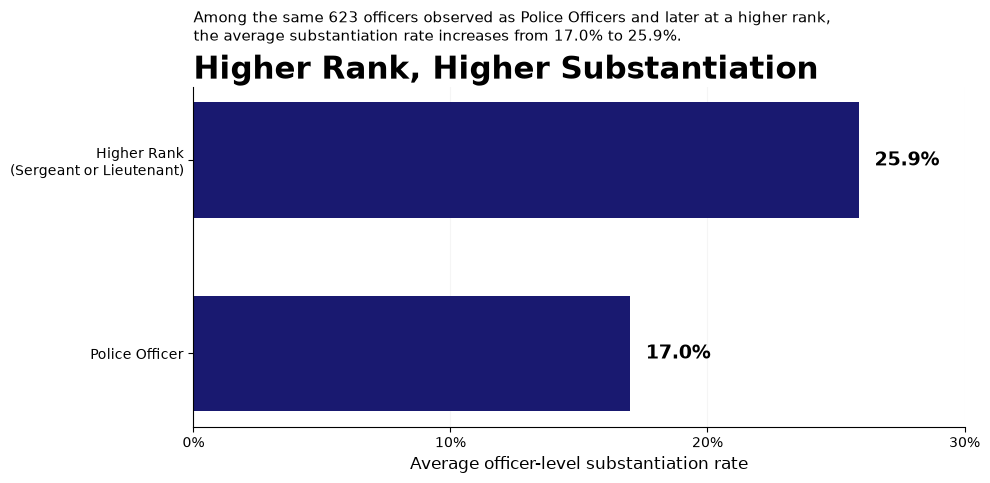

In [12]:
import matplotlib.pyplot as plt

ranks = ["Police Officer", "Higher Rank\n(Sergeant or Lieutenant)"]
rates = [17.0, 25.9]

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(
    ranks,
    rates,
    height=0.6,
    color="midnightblue"
)

# labels
for bar, rate in zip(bars, rates):
    ax.text(
        rate + 0.6,
        bar.get_y() + bar.get_height() / 2,
        f"{rate:.1f}%",
        va="center",
        fontsize=14,
        fontweight="bold"
    )

# Axis
ax.set_xlim(0, 30)
ax.set_xticks([0, 10, 20, 30])
ax.set_xticklabels(["0%", "10%", "20%", "30%"])

ax.set_xlabel(
    "Average officer-level substantiation rate",
    fontsize=12
)

# Title
ax.set_title(
    "Higher Rank, Higher Substantiation",
    fontsize=22,
    fontweight="bold",
    loc="left"
)

# Subtitle
ax.text(
    0,
    1.62,
    "Among the same 623 officers observed as Police Officers and later at a higher rank,\n"
    "the average substantiation rate increases from 17.0% to 25.9%.",
    fontsize=11
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(axis="x", alpha=0.12)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [13]:
for higher_rank in ["Sergeant", "Lieutenant"]:
    subset = data[
        data["rank_incident"].isin(
            ["Police Officer", higher_rank]
        )
    ].copy()

    rates = (
        subset
        .groupby(["unique_mos_id", "rank_incident"])
        .agg(
            rate=("substantiated", "mean"),
            first_year=("year_received", "min")
        )
        .reset_index()
    )

    wide = rates.pivot(
        index="unique_mos_id",
        columns="rank_incident",
        values=["rate", "first_year"]
    )

    matched_rank = wide.dropna(
        subset=[
            ("rate", "Police Officer"),
            ("rate", higher_rank)
        ]
    )

    matched_rank = matched_rank[
        matched_rank[("first_year", higher_rank)]
        >= matched_rank[("first_year", "Police Officer")]
    ]

    po = 100 * matched_rank[("rate", "Police Officer")].mean()
    higher = 100 * matched_rank[("rate", higher_rank)].mean()

    print(
        f"{higher_rank}: N={len(matched_rank)}, "
        f"PO={po:.1f}%, "
        f"Higher={higher:.1f}%, "
        f"Difference={higher-po:+.1f} pp"
    )

Sergeant: N=594, PO=16.5%, Higher=25.2%, Difference=+8.7 pp
Lieutenant: N=124, PO=18.8%, Higher=20.9%, Difference=+2.1 pp


In [14]:
# Which higher ranks does each matched officer appear at?

matched_ids = matched_higher.index

rank_presence = (
    data[
        data["unique_mos_id"].isin(matched_ids)
        & data["rank_incident"].isin(["Sergeant", "Lieutenant"])
    ]
    .groupby("unique_mos_id")["rank_incident"]
    .agg(lambda x: set(x))
)


def classify_higher_ranks(ranks):
    if ranks == {"Sergeant"}:
        return "Sergeant only"
    elif ranks == {"Lieutenant"}:
        return "Lieutenant only"
    elif ranks == {"Sergeant", "Lieutenant"}:
        return "Sergeant + Lieutenant"
    else:
        return "Other"


rank_groups = rank_presence.apply(classify_higher_ranks)

print(rank_groups.value_counts())
print()
print("Total:", len(rank_groups))

rank_incident
Sergeant only            499
Sergeant + Lieutenant     95
Lieutenant only           29
Name: count, dtype: int64

Total: 623


In [15]:
# Add group membership to the matched dataset

diagnostic = matched_higher.copy()

diagnostic["higher_rank_path"] = rank_groups


# Compare PO and combined higher-rank rates
# separately for each career-path group

for group in [
    "Sergeant only",
    "Lieutenant only",
    "Sergeant + Lieutenant"
]:
    subset = diagnostic[
        diagnostic["higher_rank_path"] == group
    ]

    po_rate = (
        100
        * subset[
            ("substantiation_rate", "Police Officer")
        ].mean()
    )

    higher_rate = (
        100
        * subset[
            ("substantiation_rate", "Higher Rank")
        ].mean()
    )

    print(group)
    print(f"  N = {len(subset)}")
    print(f"  Police Officer = {po_rate:.1f}%")
    print(f"  Higher Rank = {higher_rate:.1f}%")
    print(f"  Difference = {higher_rate - po_rate:+.1f} pp")
    print()

Sergeant only
  N = 499
  Police Officer = 16.5%
  Higher Rank = 27.6%
  Difference = +11.0 pp

Lieutenant only
  N = 29
  Police Officer = 26.1%
  Higher Rank = 25.4%
  Difference = -0.7 pp

Sergeant + Lieutenant
  N = 95
  Police Officer = 16.5%
  Higher Rank = 17.3%
  Difference = +0.7 pp

